# $\epsilon$-Constraint

Método introducido en Haimes et al. (1971), ==una== de las ==funciones objetivo es seleccionada para ser optimizada== y ==el resto== se convierten en ==restricciones al establecer un límite superior.==

Ahora el problema toma la siguiente forma:

$$
\begin{aligned}
& \text{minimizar} \quad f_l(x)\\
& \text{sujeto a} \quad f_j(x) \leq \epsilon_j \quad \text{para todo} \quad j=1,\ldots,k, j\neq l
\end{aligned}

$$

Donde:
- $f_l(x)$ corresponde a la variable seleccionada donde $l \in \left\{ 1,\ldots, k\right\}$. 
- $f_j(x)$ al resto de las funciones objetivos y,
- $\epsilon_j$ corresponde al valor del límite superior establecido como $f_j(x) \leq \epsilon_j$.


*Nota: Existe otra formulación donde se utilizan igualdades que son optimos de Pareto con ciertos supuestos.*

## Ejemplo de implementación

```python
    def epsilonConstrint_MOP1(self) -> np.ndarray:
        """
        Ejemplo para MOP1

        Calcula un punto débil de pareto por cada iteración sobre
        epsilon. 

        Se selecciona una función objetivo (fl) y las demás funciones (fj)
        funjen como restricciones, donde fj <= ej

        Cada función restriccion debe tener su propio epsilon

        """

        # Frente de pareto
        front = []

        # Punto fijo - requisito de scipy
        x0 = [(0.0)]

        # Recorremos epsilon uniformement desde 0 hasta 6 (31 puntos)
        for eps in np.linspace(0.0, 6.0, 31):     # rango elegido a ojo

            r = minimize(self.fl, x0, bounds=[self.func_bounds], method="SLSQP", constraints=[
                # fj <= ej  ->. fj - ej <= 0
                {"type": "ineq", "fun": lambda x, e=eps: e - self.fj[0](x)}
            ])

            # Descarta infactibles / fallos -> que talvez el solver no convergio
            if r.success and self.fj[0](r.x) <= eps + 1e-6:   
                front.append((float(self.fl(r.x)), float(self.fj[0](r.x))))

        # quedarse sin duplicados
        return np.unique(np.round(front, 6), axis=0)
```

## Ejemplo de ejecución

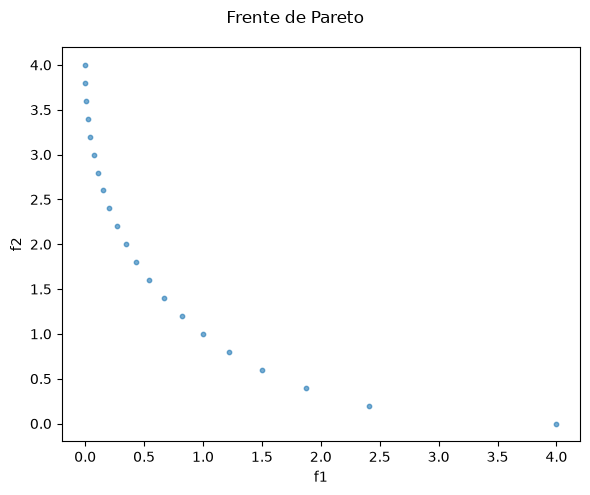

In [1]:
from functions.mop1 import MOP1
from utils.graphs import plot_points
from algorithms.epsilonConstraint import EpsilonConstraint

mop1 = MOP1()

epsilonConstr = EpsilonConstraint(fl=mop1.f1, fj=[mop1.f2], bounds=mop1.domain)
pts = epsilonConstr.MOP1()

fig = plot_points(pts, names=["f1", "f2"], title="Frente de Pareto")